# Прогноз отмены бронирования для сети отелей UrbanStay

Задача. Сеть отелей среднего сегмента теряет выручку из-за поздних отмен: отменяется более 30% броней, загрузка держится на 60–70% вместо плановых 80%. Текущее решение — овербукинг вслепую. Нужен инструмент, который заранее выявляет рискованные брони.

Данные. Две таблицы в PostgreSQL: hotel_bookings — 35 341 бронирование (параметры брони, даты, стоимость, целевой признак booking_status); hotel_reviews — 25 177 отзывов (оценка проживания, текст, дата отзыва, customer_id).

Критерий успеха — не точность, а деньги: относительный IR ≥ 50%, доля пропущенных отмен ≤ 10%, падение загрузки не более 8%.

## Перевод бизнес-задачи на язык машинного обучения

Задача бинарной классификации: booking_status → 1 (отказ_брони) / 0 (нет_отказа).

Метрика оптимизации — Incremental Revenue, бизнес-метрика с несимметричной ценой ошибок: FN стоит 64 500 ₽, FP — 7 000 ₽. Пропущенная отмена дороже ложной тревоги почти в 10 раз, поэтому оптимальный порог будет заметно ниже 0.5.

План: склейка таблиц через merge_asof, признаки из дат и истории клиента, векторизация отзывов TF-IDF, сравнение градиентных бустингов и Random Forest, подбор гиперпараметров Optuna, калибровка вероятностей, поиск порога по IR.

## Загрузка необходимых библиотек

In [4]:
import warnings
import shap
import optuna
from urllib.parse import quote_plus

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import OrdinalEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import confusion_matrix, roc_auc_score, classification_report

from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

In [5]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

In [6]:
warnings.filterwarnings('ignore')

RANDOM_STATE = 42

In [7]:
AVG_REV = 64_500 # доход от сдачи номера
COST_FP = 7_000 # компенсация за ложную отмену
LOST_REV = 64_500 # упущенный доход от пропущенной отмены
PER_REBOOKING = 45_000 # доход от перепродажи вовремя пойманной отмены

## Этап 1: подготовка данных

### Загрузка данных

In [ ]:
import os
from pathlib import Path

# Данные берутся из CSV в папке data/, если они там есть,
# иначе — из PostgreSQL. Параметры подключения задаются через переменные окружения.
DATA = Path('data')

if (DATA / 'hotel_bookings.csv').exists():
    bookings = pd.read_csv(DATA / 'hotel_bookings.csv')
    reviews = pd.read_csv(DATA / 'hotel_reviews.csv')
else:
    connection_string = (
        f"postgresql+psycopg2://{os.getenv('DB_USER')}:{quote_plus(os.getenv('DB_PASSWORD', ''))}"
        f"@{os.getenv('DB_HOST')}:{os.getenv('DB_PORT', '6432')}/{os.getenv('DB_NAME')}"
    )
    engine = create_engine(connection_string, pool_pre_ping=True)
    with engine.connect() as conn:
        bookings = pd.read_sql_query('SELECT * FROM hotel_bookings', con=conn)
        reviews = pd.read_sql_query('SELECT * FROM hotel_reviews', con=conn)

In [9]:
bookings.head()

,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests
0,INN00000,2020-07-08,корпоративное_бронирование,300,0,False,0,0,нет_отказа,6700.0,21,1,0,тип_питания_2,False,тип_1,0
1,INN00001,2021-09-19,корпоративное_бронирование,3,0,True,0,1,нет_отказа,62300.0,15,5,2,тип_питания_2,False,тип_1,1
2,INN00002,2022-11-19,корпоративное_бронирование,3,0,True,0,2,нет_отказа,46900.0,96,5,2,тип_питания_1,False,тип_1,0
3,INN00003,2017-02-11,онлайн_бронирование,2,0,False,0,0,нет_отказа,53600.0,150,6,2,тип_питания_1,False,тип_1,0
4,INN00004,2019-03-06,корпоративное_бронирование,1,0,True,1,1,нет_отказа,46900.0,96,5,2,тип_питания_1,False,тип_1,1


In [10]:
bookings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35341 entries, 0 to 35340
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   booking_id                 35341 non-null  object 
 1   booking_date               35341 non-null  object 
 2   sales_channel              35341 non-null  object 
 3   adult_count                35341 non-null  int64  
 4   child_count                35341 non-null  int64  
 5   returning_customer         35341 non-null  bool   
 6   previous_cancellations     35341 non-null  int64  
 7   previous_no_shows          35341 non-null  int64  
 8   booking_status             35341 non-null  object 
 9   booking_value              35341 non-null  float64
 10  days_until_checkin         35341 non-null  int64  
 11  weekday_nights             35341 non-null  int64  
 12  weekend_nights             35341 non-null  int64  
 13  meal_plan                  35341 non-null  obj

In [11]:
reviews.head()

,customer_id,booking_id,review_date,stay_rating,review_text
0,C0001,INN00000,2020-08-21,3,"Неплохо. тихо и спокойно, но отсутствие фена в..."
1,C0001,INN00001,2021-10-15,3,"Неплохо. красивое оформление территории, но не..."
2,C0001,INN00002,2023-03-08,4,Отличный отель! удобные парковочные места. зде...
3,C0002,INN00003,2017-08-13,3,"Неплохо. тёплый приём, но неисправная сантехни..."
4,C0003,INN00004,2019-07-12,4,Отличный отель! качественная косметика в ванно...


In [12]:
reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25177 entries, 0 to 25176
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   customer_id  25177 non-null  object
 1   booking_id   25177 non-null  object
 2   review_date  25177 non-null  object
 3   stay_rating  25177 non-null  int64 
 4   review_text  25177 non-null  object
dtypes: int64(1), object(4)
memory usage: 983.6+ KB


### Исследовательский анализ данных и предобработка

In [13]:
bookings['booking_date'] = pd.to_datetime(bookings['booking_date'])
reviews['review_date'] = pd.to_datetime(reviews['review_date'])

print('Пропуски в датах:', bookings['booking_date'].isna().sum())
print(bookings['booking_date'].min(), '—', bookings['booking_date'].max())
print(reviews['review_date'].min(), '—', reviews['review_date'].max())
print()
print(bookings['booking_date'].min()-reviews['review_date'].min())
print(bookings['booking_date'].max()-reviews['review_date'].max())

Пропуски в датах: 0
2017-01-01 00:00:00 — 2025-10-22 00:00:00
2017-01-17 00:00:00 — 2026-03-03 00:00:00

-16 days +00:00:00
-132 days +00:00:00


Формат дат изменен, период в таблице review_date меньше: на 16 дней позже начинается, на 132 дня раньше заканчивается, но находится внутри временного периода из таблицы booking_date.

In [14]:
before = len(bookings)
bookings = bookings.drop_duplicates().reset_index(drop=True)

print(f'{before} → {len(bookings)}, удалено {before - len(bookings)}, {before/(before - len(bookings)): .2f}%')


35341 → 30733, удалено 4608,  7.67%


Удалено 4608 явных дубликатов, примерно 7.67% от общего числа значений.

In [15]:
ids_b = set(bookings['booking_id'])
ids_r = set(reviews['booking_id'])
print('Отзывов с booking_id из bookings:', len(ids_b & ids_r))
print('Отзывов с "чужим" booking_id:', len(ids_r - ids_b))
print('Уникальных клиентов:', reviews['customer_id'].nunique())

Отзывов с booking_id из bookings: 21883
Отзывов с "чужим" booking_id: 0
Уникальных клиентов: 13429


In [16]:
print(bookings['booking_status'].value_counts())
print(bookings['booking_status'].value_counts(normalize=True).round(3))

нет_отказа     21883
отказ_брони     8850
Name: booking_status, dtype: int64
нет_отказа     0.712
отказ_брони    0.288
Name: booking_status, dtype: float64


Что ожидаемо, распределение целевой переменной неравномерное.

In [17]:
for col in ['sales_channel', 'meal_plan', 'room_type']:
    print(f'\n--- {col} ---')
    print(bookings[col].value_counts(dropna=False))


--- sales_channel ---
офлайн_бронирование           10447
корпоративное_бронирование    10228
онлайн_бронирование           10058
Name: sales_channel, dtype: int64

--- meal_plan ---
тип_питания_1    23604
не выбран         3868
тип_питания_2     2826
не выбрант         430
тип_питания_3        5
Name: meal_plan, dtype: int64

--- room_type ---
тип_1    23687
тип_4     5243
тип_6      832
тип_2      578
тип_5      242
тип_7      143
тип_3        8
Name: room_type, dtype: int64


Распределение по каналам бронирования равномерное, по типу питания и номера неравномерное, есть как сильно доминирующие группы, так и очень малочисленные. Также в типе питания опечатка, из-за которой отсутствие питание разделилось на две группы.

In [18]:
bookings['meal_plan'] = bookings['meal_plan'].replace({'не выбрант': 'не выбран'})
print(bookings['meal_plan'].value_counts())

тип_питания_1    23604
не выбран         4298
тип_питания_2     2826
тип_питания_3        5
Name: meal_plan, dtype: int64


In [19]:
num_cols = [
    'adult_count', 'child_count', 'previous_cancellations', 'previous_no_shows',
    'booking_value', 'days_until_checkin', 'weekday_nights', 'weekend_nights',
    'customer_special_requests', 
]
display(bookings[num_cols].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
adult_count,30733.0,14.08,48.83,1.0,1.0,2.0,3.0,300.0
child_count,30733.0,0.36,0.58,0.0,0.0,0.0,1.0,2.0
previous_cancellations,30733.0,0.36,0.63,0.0,0.0,0.0,1.0,5.0
previous_no_shows,30733.0,0.84,0.93,0.0,0.0,1.0,1.0,5.0
booking_value,30733.0,61679.17,42737.29,0.0,33500.0,60300.0,80400.0,417221.2
days_until_checkin,30733.0,100.60,71.93,2.0,45.0,90.0,144.0,300.0
weekday_nights,30733.0,6.54,3.34,1.0,5.0,6.0,9.0,15.0
weekend_nights,30733.0,1.95,1.48,0.0,0.0,2.0,2.0,6.0
customer_special_requests,30733.0,0.62,0.78,0.0,0.0,0.0,1.0,5.0


Из странностей - максимум 300 взрослых в одной брони, необходимо проверить на ошибку.

In [20]:
big = bookings['adult_count'] > 4
print('Строк:', big.sum())
print(bookings.loc[big, 'adult_count'].value_counts().sort_index())
print(bookings.loc[big, 'booking_status'].value_counts(normalize=True).round(3))
display(bookings.loc[big, ['adult_count', 'booking_value', 'weekday_nights', 'room_type']].head(10))

Строк: 2151
100    884
200    872
300    395
Name: adult_count, dtype: int64
нет_отказа     0.706
отказ_брони    0.294
Name: booking_status, dtype: float64


,adult_count,booking_value,weekday_nights,room_type
0,300,6700.0,1,тип_1
44,200,173223.4,13,тип_4
79,100,117039.7,8,тип_1
83,200,46900.0,5,тип_4
90,100,33500.0,5,тип_1
98,100,53600.0,6,тип_1
110,100,17800.0,2,тип_1
142,100,93800.0,10,тип_1
146,200,33500.0,5,тип_2
161,200,46900.0,5,тип_1


Очевидно ошибка произошла из-за домножения на 100, так как стоимость и тип номера у таких выбросов не имеют каких-либо отличительных особенностей, а также свыше 4 есть значения только 100, 200 и 300, без промежуточных.

In [21]:
bookings.loc[big, 'adult_count'] = bookings.loc[big, 'adult_count'] // 100

print(bookings['adult_count'].value_counts().sort_index())
print(bookings['adult_count'].describe().round(2))

1    12374
2    12144
3     6215
Name: adult_count, dtype: int64
count    30733.00
mean         1.80
std          0.75
min          1.00
25%          1.00
50%          2.00
75%          2.00
max          3.00
Name: adult_count, dtype: float64


In [22]:
# Логические противоречия
print('Броней без взрослых:', (bookings['adult_count'] == 0).sum())
print('Нулевая стоимость:', (bookings['booking_value'] == 0).sum())
print('Отрицательная стоимость:', (bookings['booking_value'] < 0).sum())
print('Ноль ночей проживания:', ((bookings['weekday_nights'] + bookings['weekend_nights']) == 0).sum())
print('Заезд раньше брони (<0 дней):', (bookings['days_until_checkin'] < 0).sum())
print('days_until_checkin > 365:   ', (bookings['days_until_checkin'] > 365).sum())

Броней без взрослых: 0
Нулевая стоимость: 1229
Отрицательная стоимость: 0
Ноль ночей проживания: 0
Заезд раньше брони (<0 дней): 0
days_until_checkin > 365:    0


In [23]:
#Проверка гипотезы: нулевая стоимость — отдельный сегмент?
mask_zero = bookings['booking_value'] == 0
print(f'Записей с нулевой стоимостью: {mask_zero.sum()}')

# Ноль при ненулевом проживании — значение невозможное
nights = bookings['weekday_nights'] + bookings['weekend_nights']
print(f'Из них с нулевым числом ночей: {(mask_zero & (nights == 0)).sum()}')

# Сравнение срезов: нулевые брони против всей выборки
compare = pd.DataFrame({
    'нулевая стоимость': bookings.loc[mask_zero, 'sales_channel'].value_counts(normalize=True),
    'вся выборка': bookings['sales_channel'].value_counts(normalize=True),
}).round(3)
display(compare)

compare_target = pd.DataFrame({
    'нулевая стоимость': bookings.loc[mask_zero, 'booking_status'].value_counts(normalize=True),
    'вся выборка': bookings['booking_status'].value_counts(normalize=True),
}).round(3)
display(compare_target)

Записей с нулевой стоимостью: 1229
Из них с нулевым числом ночей: 0


,нулевая стоимость,вся выборка
офлайн_бронирование,0.345,0.340
корпоративное_бронирование,0.334,0.333
онлайн_бронирование,0.321,0.327


,нулевая стоимость,вся выборка
нет_отказа,0.709,0.712
отказ_брони,0.291,0.288


Выявлено 1229 записей с нулевой стоимостью бронирования. Ноль здесь не является корректным значением: все такие брони содержат ненулевое количество ночей проживания, то есть стоимость не может отсутствовать физически. Проверка показала, что нулевые значения не образуют отдельного сегмента — распределение по каналам продаж (34.5% / 33.4% / 32.1%) и доля отмен (29.1% против 28.8% по выборке) совпадают с общими. Следовательно, это не бизнес-логика вроде оплаты бонусами, а дефект данных.

Удалять записи нецелесообразно: теряются 4% наблюдений со всеми остальными корректными признаками. Заполнение медианой или средним подставило бы вымышленную сумму. Поэтому нули заменены на NaN — градиентные бустинги обрабатывают пропуски нативно и сами определяют, в какую ветку дерева направлять неизвестное значение.

In [24]:
bookings.loc[mask_zero, 'booking_value'] = np.nan

print('Пропусков в booking_value:', bookings['booking_value'].isna().sum())
print(bookings['booking_value'].describe().round(1))

Пропусков в booking_value: 1229
count     29504.0
mean      64248.4
std       41683.1
min        6700.0
25%       46900.0
50%       60300.0
75%       89000.0
max      417221.2
Name: booking_value, dtype: float64


In [25]:
bookings['target'] = bookings['booking_status'].map({'нет_отказа': 0, 'отказ_брони': 1})
base_rate = bookings['target'].mean()
print('Базовый уровень отмен:', round(base_rate, 3))

Базовый уровень отмен: 0.288


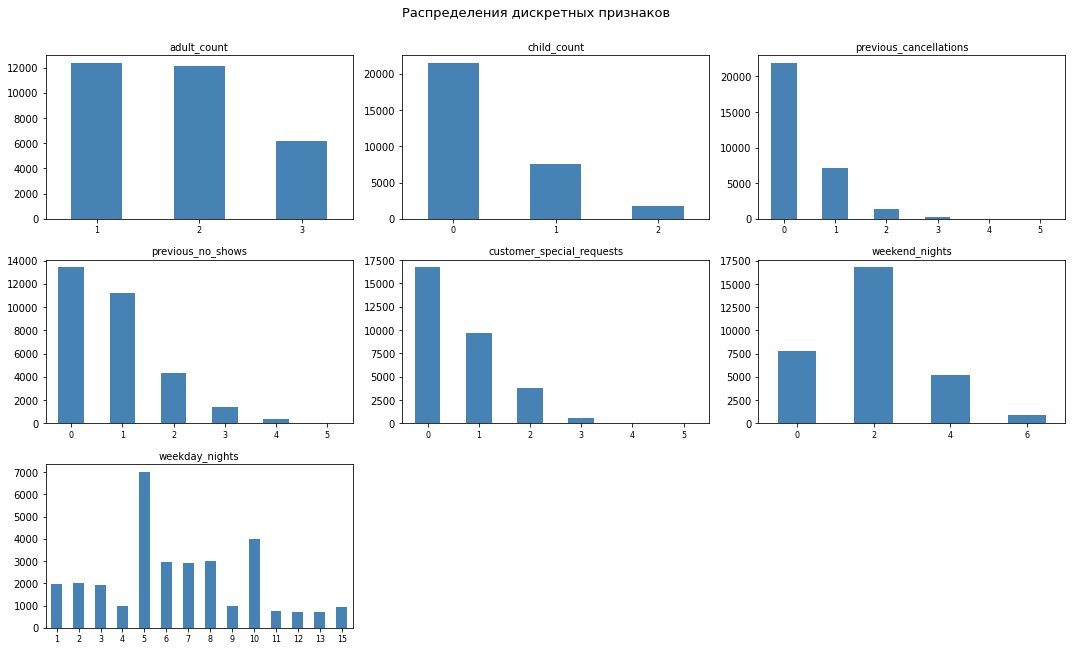

In [26]:
discrete_cols = ['adult_count', 'child_count', 'previous_cancellations',
                 'previous_no_shows', 'customer_special_requests',
                 'weekend_nights', 'weekday_nights']

fig, axes = plt.subplots(3, 3, figsize=(15, 9))
for ax, col in zip(axes.flat, discrete_cols):
    bookings[col].value_counts().sort_index().plot(kind='bar', ax=ax, color='steelblue')
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('')
    ax.tick_params(axis='x', labelrotation=0, labelsize=8)

for ax in axes.flat[len(discrete_cols):]:
    ax.axis('off')

plt.suptitle('Распределения дискретных признаков', y=1.0, fontsize=13)
plt.tight_layout()
plt.show()

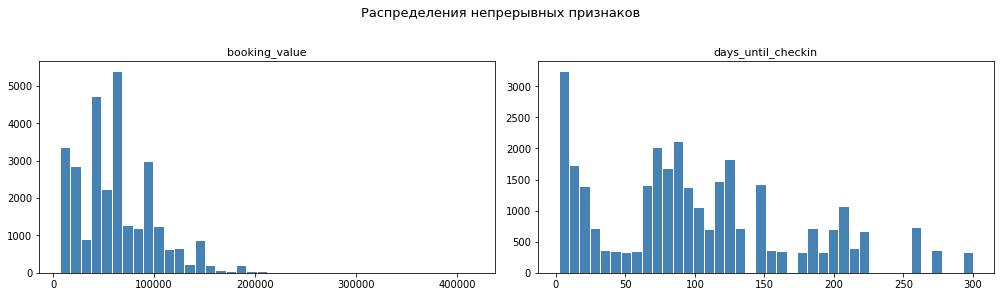

In [27]:
continuous_cols = ['booking_value', 'days_until_checkin']

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, continuous_cols):
    ax.hist(bookings[col].dropna(), bins=40, color='steelblue', edgecolor='white')
    ax.set_title(col, fontsize=11)

plt.suptitle('Распределения непрерывных признаков', y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

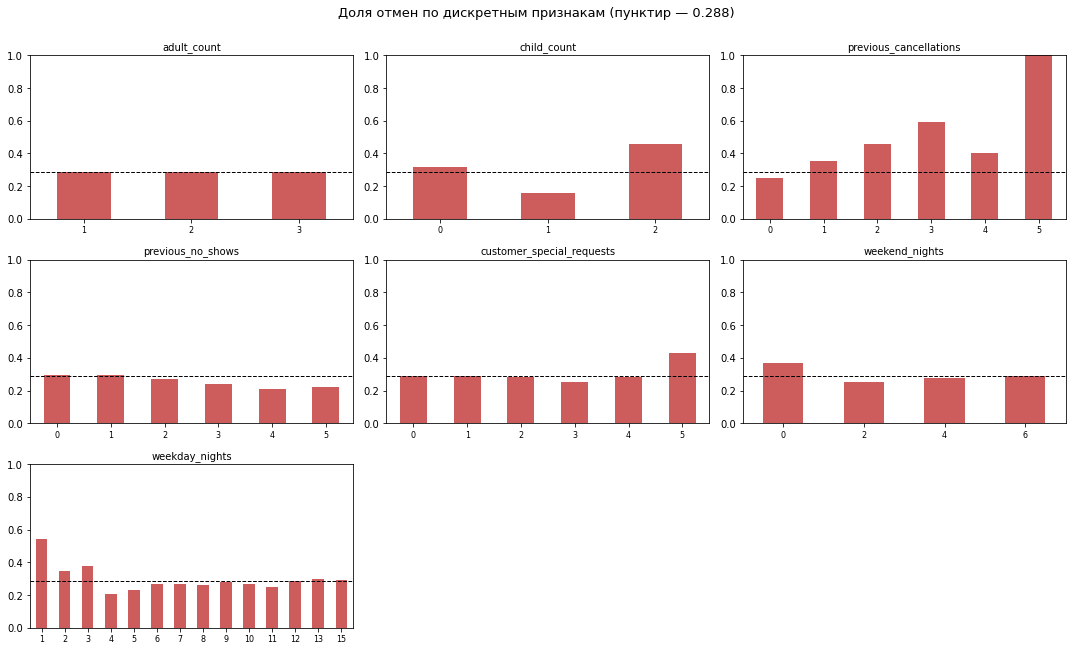

In [28]:
base_rate = bookings['target'].mean()

fig, axes = plt.subplots(3, 3, figsize=(15, 9))
for ax, col in zip(axes.flat, discrete_cols):
    bookings.groupby(col)['target'].mean().plot(kind='bar', ax=ax, color='indianred')
    ax.axhline(base_rate, ls='--', c='black', lw=1)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('')
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', labelrotation=0, labelsize=8)

for ax in axes.flat[len(discrete_cols):]:
    ax.axis('off')

plt.suptitle(f'Доля отмен по дискретным признакам (пунктир — {base_rate:.3f})',
             y=1.0, fontsize=13)
plt.tight_layout()
plt.show()

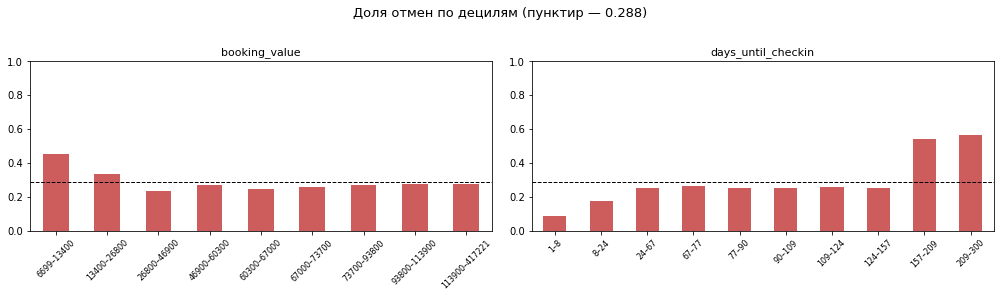

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, continuous_cols):
    bins = pd.qcut(bookings[col], 10, duplicates='drop')
    grp = bookings.groupby(bins)['target'].mean()
    grp.index = [f'{int(i.left)}–{int(i.right)}' for i in grp.index]

    grp.plot(kind='bar', ax=ax, color='indianred')
    ax.axhline(base_rate, ls='--', c='black', lw=1)
    ax.set_title(col, fontsize=11)
    ax.set_xlabel('')
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', labelrotation=45, labelsize=8)

plt.suptitle(f'Доля отмен по децилям (пунктир — {base_rate:.3f})', y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

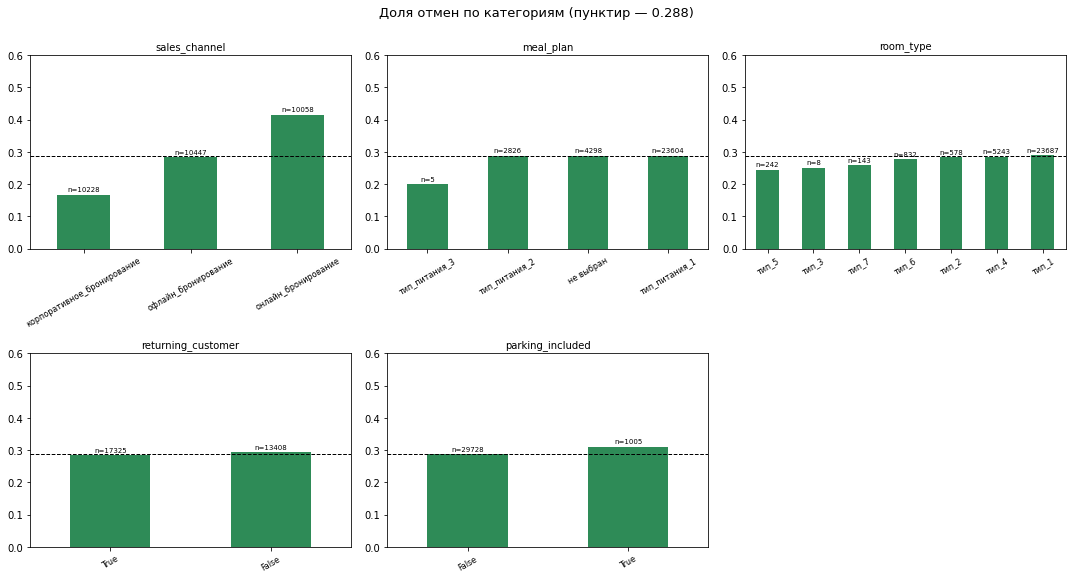

In [30]:
cat_cols = ['sales_channel', 'meal_plan', 'room_type',
            'returning_customer', 'parking_included']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, cat_cols):
    grp = bookings.groupby(col)['target'].agg(['mean', 'size']).sort_values('mean')
    grp['mean'].plot(kind='bar', ax=ax, color='seagreen')
    ax.axhline(base_rate, ls='--', c='black', lw=1)

    # подписываем объём группы — доля по 10 наблюдениям ничего не значит
    for i, (m, n) in enumerate(zip(grp['mean'], grp['size'])):
        ax.text(i, m + 0.01, f'n={n}', ha='center', fontsize=7)

    ax.set_title(col, fontsize=10)
    ax.set_xlabel('')
    ax.set_ylim(0, max(0.6, grp['mean'].max() * 1.25))
    ax.tick_params(axis='x', labelrotation=30, labelsize=8)

axes.flat[-1].axis('off')
plt.suptitle(f'Доля отмен по категориям (пунктир — {base_rate:.3f})', y=1.0, fontsize=13)
plt.tight_layout()
plt.show()

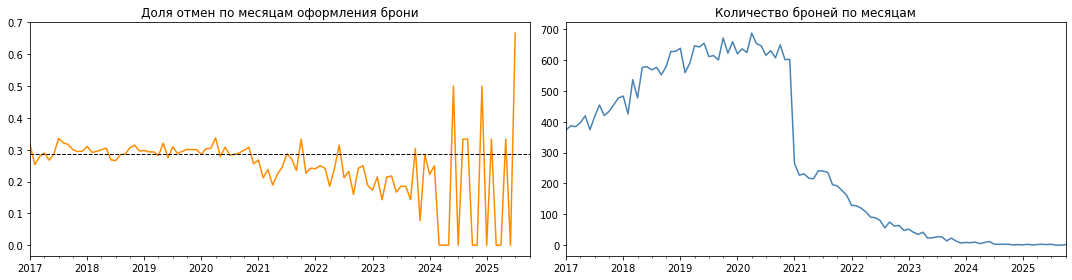

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

by_month = bookings.set_index('booking_date').resample('M')['target'].agg(['mean', 'size'])
by_month['mean'].plot(ax=axes[0], color='darkorange')
axes[0].axhline(base_rate, ls='--', c='black', lw=1)
axes[0].set_title('Доля отмен по месяцам оформления брони')
axes[0].set_xlabel('')

by_month['size'].plot(ax=axes[1], color='steelblue')
axes[1].set_title('Количество броней по месяцам')
axes[1].set_xlabel('')

plt.tight_layout()
plt.show()

In [32]:
# meal_plan: тип_питания_3-5 наблюдений
bookings['meal_plan'] = bookings['meal_plan'].replace({'тип_питания_3': 'тип_питания_2'})

# room_type: тип_3 (8), тип_5 (242), тип_7 (143)
rare_rooms = ['тип_3', 'тип_5', 'тип_7']
bookings['room_type'] = bookings['room_type'].replace(dict.fromkeys(rare_rooms, 'прочее'))

print(bookings['meal_plan'].value_counts())
print(bookings['room_type'].value_counts())

тип_питания_1    23604
не выбран         4298
тип_питания_2     2831
Name: meal_plan, dtype: int64
тип_1     23687
тип_4      5243
тип_6       832
тип_2       578
прочее      393
Name: room_type, dtype: int64


**Выводы по графическому анализу**

Признаки с сильной предсказательной силой:
- days_until_checkin — ключевой фактор. Доля отмен растёт монотонно с 10% (заезд через 1–8 дней) до 55% (через 209–300 дней). Разница  почти в 6 раз: чем больше горизонт планирования, тем выше риск изменения планов клиента.
- sales_channel — корпоративные брони отменяются в 17% случаев, офлайн — 29%, онлайн — 41%. Онлайн-канал даёт в 2.4 раза больше отмен, чем корпоративный.
- previous_cancellations — 24% отмен у клиентов без истории отказов, 46% при двух прошлых отменах, 60% при трёх. 
- weekday_nights — брони на 1 будний день отменяются в 55% случаев против базовых 29%. С ростом длительности показатель снижается до среднего уровня.
- child_count — немонотонная зависимость: 31% при отсутствии детей, 15% при одном ребёнке, 45% при двух.

Признаки со слабой дифференциацией: adult_count, returning_customer, parking_included, previous_no_shows, customer_special_requests, meal_plan, room_type — доля отмен во всех группах близка к базовому уровню 28.8%. Признаки сохранены для моделирования, но существенного вклада не ожидается.

Временная структура данных:
- Данные охватывают период с 2017 года и распределены крайне неравномерно. Объём бронирований достигает пика в 2019–2020 годах (около 650 в месяц), затем резко падает в начале 2021 года до 200 и к 2024 году снижается практически до нуля.
- Динамика доли отмен не подтверждает утверждение заказчика о росте отмен за последние два года. До 2021 года показатель стабилен на уровне 28–30%, после — снижается до 20%. Резкие колебания от 0% до 100% в 2024–2025 годах объясняются малым числом наблюдений в этих месяцах и не отражают реальной тенденции.

Практическое следствие: признак «год бронирования» в модель не включается. Модель обучается на исторических данных, но применяться будет к будущим периодам, отсутствующим в обучающей выборке. Использование года привело бы к завышению метрик на тесте при неработоспособности модели в продуктивной среде. Циклические временные признаки (месяц, сезон) допустимы и будут созданы на этапе feature engineering.

Обработка редких категорий:
Категории с малым числом наблюдений объединены: тип_питания_3 (5 записей) присоединён к тип_питания_2; типы номеров тип_3 (8), тип_7 (143) и тип_5 (242) объединены в категорию «прочее». При разбиении выборки в пропорции 60/20/20 такие категории рискуют полностью попасть в одну из выборок, что приводит к переобучению на них и к встрече с неизвестным значением на тесте.

### Объединение таблиц

In [33]:
booking_to_customer = reviews[['booking_id', 'customer_id']].drop_duplicates('booking_id')
bookings = bookings.merge(booking_to_customer, on='booking_id', how='left')

print('Клиент определён:', bookings['customer_id'].notna().sum(), 'из', len(bookings))

Клиент определён: 21883 из 30733


In [34]:
left = bookings.sort_values('booking_date').reset_index(drop=True)
right = (reviews[['customer_id', 'review_date', 'stay_rating', 'review_text']]
         .sort_values('review_date')
         .reset_index(drop=True))

assert left['booking_date'].is_monotonic_increasing
assert right['review_date'].is_monotonic_increasing

In [35]:
merged = pd.merge_asof(
    left, right,
    left_on='booking_date',
    right_on='review_date',
    by='customer_id',
    direction='backward',
    allow_exact_matches=False,
)

print('Строк:', len(merged), '(было', len(bookings), ')')
print('Отзыв подтянут:', merged['review_date'].notna().sum())

Строк: 30733 (было 30733 )
Отзыв подтянут: 8328


In [36]:
diff = (merged['booking_date'] - merged['review_date']).dt.days
print('Отзыв позже брони:  ', (diff < 0).sum())
print('Отзыв в день брони: ', (diff == 0).sum())
print('\nРазница в днях:')
print(diff.describe().round(1))

has_review = merged['review_date'].notna()
print('\nСвязь наличия отзыва со статусом:')
print(pd.crosstab(has_review, merged['booking_status'], normalize='index').round(3))

Отзыв позже брони:   0
Отзыв в день брони:  0

Разница в днях:
count    8328.0
mean      256.2
std       117.4
min         1.0
25%       167.0
50%       254.0
75%       347.0
max       681.0
dtype: float64

Связь наличия отзыва со статусом:
booking_status  нет_отказа  отказ_брони
review_date                            
False                0.605        0.395
True                 1.000        0.000


In [37]:
merged['days_since_review'] = (merged['booking_date'] - merged['review_date']).dt.days
merged['stay_rating'] = merged['stay_rating'].fillna(-1)
merged['review_text'] = merged['review_text'].fillna('')

print('Доля броней с историей отзывов:', round(has_review.mean(), 3))
print(merged['stay_rating'].value_counts().sort_index())

Доля броней с историей отзывов: 0.271
-1.0    22405
 2.0      178
 3.0     4772
 4.0     3302
 5.0       76
Name: stay_rating, dtype: int64


In [38]:
merged.head()

,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,...,meal_plan,parking_included,room_type,customer_special_requests,target,customer_id,review_date,stay_rating,review_text,days_since_review
0,INN17387,2017-01-01,офлайн_бронирование,2,0,True,1,1,нет_отказа,73700.0,...,тип_питания_1,False,тип_1,2,0,C9324,NaT,-1.0,,NaN
1,INN07784,2017-01-01,онлайн_бронирование,2,0,False,0,0,отказ_брони,166363.4,...,тип_питания_2,False,тип_1,0,1,NaN,NaT,-1.0,,NaN
2,INN28926,2017-01-01,онлайн_бронирование,3,0,False,0,0,отказ_брони,89000.0,...,тип_питания_1,False,тип_1,1,1,NaN,NaT,-1.0,,NaN
3,INN11824,2017-01-01,корпоративное_бронирование,3,0,False,0,0,нет_отказа,6700.0,...,тип_питания_1,False,тип_4,1,0,C6306,NaT,-1.0,,NaN
4,INN21754,2017-01-01,онлайн_бронирование,3,2,False,0,0,нет_отказа,67000.0,...,тип_питания_2,False,тип_2,0,0,C11662,NaT,-1.0,,NaN


Объединение выполнено методом merge_asof: для каждой брони подтягивается ближайший предшествующий отзыв того же клиента. Идентификатор клиента отсутствует в таблице бронирований, поэтому восстановлен из таблицы отзывов через booking_id.

 Параметр allow_exact_matches=False исключает отзывы, датированные днём бронирования: такой отзыв означал бы, что гость уже проживал в отеле. Проверка подтвердила корректность — нет ни одного случая, когда отзыв датирован позже или в день брони.

 Прошлый отзыв найден у 8328 броней (27.1%). Пропуски заполнены: stay_rating = -1 (шкала оценок 2–5, значение не пересекается с реальными), review_text — пустой строкой для последующей векторизации. days_since_review оставлен с пропусками — градиентные бустинги обрабатывают их нативно.

### Создание новых признаков

In [39]:
df = merged.copy()
df['checkin_date'] = df['booking_date'] + pd.to_timedelta(df['days_until_checkin'], unit='D')

In [40]:
# 2. Сезонность по месяцу заезда
def get_season(month):
    if month in (6, 7, 8):
        return 'летний'
    if month in (12, 1):
        return 'новогодний'
    return 'другой'

df['checkin_month'] = df['checkin_date'].dt.month
df['season'] = df['checkin_month'].map(get_season)

In [41]:
# 3. Общая длительность проживания
df['total_nights'] = df['weekday_nights'] + df['weekend_nights']

In [42]:
# 4. Доля выходных в поездке — отличает отдых от командировки
df['weekend_ratio'] = (df['weekend_nights'] / df['total_nights']).round(3)

In [43]:
# 5. Всего гостей и признак семейной поездки
df['total_guests'] = df['adult_count'] + df['child_count']
df['is_family'] = (df['child_count'] > 0).astype(int)

In [44]:
# 6. Надёжность клиента: сколько раз доехал против того, сколько отменил
df['reliability'] = df['previous_no_shows'] - df['previous_cancellations']
df['has_history'] = ((df['previous_no_shows'] + df['previous_cancellations']) > 0).astype(int)

In [45]:
# 7. День недели заезда
df['checkin_weekday'] = df['checkin_date'].dt.dayofweek

print(df[['checkin_date', 'season', 'total_nights', 'weekend_ratio',
          'total_guests', 'reliability']].head())

  checkin_date  season  total_nights  weekend_ratio  total_guests  reliability
0   2017-03-21  другой            11          0.182             2            0
1   2017-03-29  другой            16          0.250             2            0
2   2017-03-27  другой            10          0.200             3            0
3   2017-03-05  другой             1          0.000             3            0
4   2017-05-05  другой            10          0.200             5            0


In [46]:
print('Примеры отзывов:')
for t in df.loc[df['review_text'] != '', 'review_text'].head(5):
    print('-', t)

print('\nДлина текстов:')
print(df.loc[df['review_text'] != '', 'review_text'].str.len().describe().round(1))

Примеры отзывов:
- Крайне недоволен. холодная еда в ресторане. завышенные цены при низком уровне сервиса Для детей ничего нет, им было скучно. В номерах холодно. второго одеяла пришлось выпрашивать
- Отличный отель! всё супер. лучший отель в этом городе — это факт! Зимой отель хорошо отапливается.
- Отличный отель! отличная шумоизоляция. здесь ценят гостей — это чувствуется Дети в восторге от игровой зоны! Зимой отель хорошо отапливается.
- Отличный отель! удобные парковочные места. буду рекомендовать как лучший выбор Зимой отель хорошо отапливается.
- Отличный отель! спа‑услуги на отлично. здесь каждый гость — особенный Зимой отель хорошо отапливается.

Длина текстов:
count    8328.0
mean       93.3
std        32.1
min        26.0
25%        67.0
50%        96.0
75%       113.0
max       196.0
Name: review_text, dtype: float64


In [47]:
# Простые признаки из текста
df['review_length'] = df['review_text'].str.len()
df['review_words'] = df['review_text'].str.split().str.len().fillna(0)
df['has_review_flag'] = (df['review_text'] != '').astype(int)

Создано 11 признаков. Ключевой — checkin_date: в данных есть только дата оформления брони, тогда как сезонность определяется датой заезда. Бронь, оформленная в январе на июль, относится к летнему сезону.

Год бронирования намеренно не создан. Анализ временной структуры показал резкую неравномерность объёма данных по годам; модель, обученная на историческом периоде, применяется к будущему, где таких значений признака не существует. Использование года завысило бы метрики без реальной предсказательной способности. Циклические составляющие даты (месяц, день недели, сезон) от этого свободны.

Колонки booking_date, checkin_date, review_date в модель не передаются — они служат только источником производных признаков.

Для векторизации нужно разделить данные на выборки, чтобы не было утечки, перенесем этот пункт сюда.

In [48]:
df = df.sort_values('booking_date').reset_index(drop=True)

n = len(df)
i_train = int(n * 0.6)
i_calib = int(n * 0.8)

df_train = df.iloc[:i_train].copy()
df_calib = df.iloc[i_train:i_calib].copy()
df_test  = df.iloc[i_calib:].copy()

for name, part in [('train', df_train), ('calib', df_calib), ('test', df_test)]:
    print(f'{name:6} {len(part):>6}  '
          f'{part["booking_date"].min().date()} — {part["booking_date"].max().date()}  '
          f'отмен {part["target"].mean():.3f}')

train   18439  2017-01-01 — 2019-11-30  отмен 0.295
calib    6147  2019-11-30 — 2020-09-20  отмен 0.298
test     6147  2020-09-20 — 2025-10-22  отмен 0.256


Разбиение выполнено хронологически, поскольку задача прогнозная: модель обучается на исторических данных и применяется к будущим бронированиям. Случайное разбиение позволило бы модели обучаться на данных более позднего периода, чем те, на которых она проверяется, и завысило бы оценку качества.

 Следствие такого подхода — выборки покрывают разные по длительности периоды: train охватывает 2 года 11 месяцев, calib — 10 месяцев, test — 5 лет. Причина в неравномерности данных: объём бронирований резко снижается после 2021 года, поэтому равные по числу строк блоки соответствуют очень разным по длительности интервалам.

In [49]:
russian_stopwords = stopwords.words('russian') + ['это', 'этот', 'весь', 'всё']
print(len(russian_stopwords), 'стоп-слов')
print(russian_stopwords[:20])

155 стоп-слов
['и', 'в', 'во', 'не', 'что', 'он', 'на', 'я', 'с', 'со', 'как', 'а', 'то', 'все', 'она', 'так', 'его', 'но', 'да', 'ты']


In [50]:
tfidf = TfidfVectorizer(
    max_features=40,
    ngram_range=(1, 1),
    min_df=20,
    max_df=0.6,
    stop_words=russian_stopwords,
    token_pattern=r'(?u)\b[а-яёА-ЯЁa-zA-Z]{3,}\b',
)

X_text_train = tfidf.fit_transform(df_train['review_text'])
X_text_calib = tfidf.transform(df_calib['review_text'])
X_text_test  = tfidf.transform(df_test['review_text'])

names = tfidf.get_feature_names_out()
print('Признаков:', len(names))
print(names)

Признаков: 40
['бельё' 'ванной' 'вернусь' 'восторге' 'второго' 'выпрашивать' 'детей'
 'дети' 'жары' 'завтрак' 'зимой' 'зоны' 'игровой' 'интернет' 'кондиционер'
 'летом' 'мебель' 'неплохо' 'номера' 'номерах' 'номере' 'одеяла'
 'освещение' 'отапливается' 'отель' 'отличный' 'персонал' 'постельное'
 'пришлось' 'расположение' 'ресепшн' 'ресторане' 'система' 'скучно'
 'спасал' 'справлялся' 'тяжело' 'удобная' 'удобные' 'холодно']


Векторизатор обучен только на тренировочной выборке: TfidfVectorizer рассчитывает IDF по всему корпусу, и обучение на полных данных перенесло бы информацию из тестовой выборки в модель.

Использованы униграммы. При ngram_range=(1, 2) более половины словаря заняли фрагменты трёх шаблонных фраз — тексты отзывов сгенерированы из повторяющихся блоков, и колонки внутри каждой цепочки оказались полностью коррелированы. Переход к отдельным словам дал 40 различных тематических признаков: услуги (завтрак, парковка, трансфер, интернет), персонал (ресепшн, персонал), состояние номера (мебель, освещение, бельё), оценочная лексика (отличный, неплохо, скучно).

Параметр max_df=0.6 отсекает слова, встречающиеся более чем в 60% отзывов, — они не различают классы.

### Анализ итоговой таблицы

In [51]:
cat_cols = ['sales_channel', 'meal_plan', 'room_type', 'season']

encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
encoder.fit(df_train[cat_cols])

for part in (df_train, df_calib, df_test):
    part[cat_cols] = encoder.transform(part[cat_cols])

print(df_train[cat_cols].head())

   sales_channel  meal_plan  room_type  season
0            2.0        1.0        1.0     0.0
1            1.0        2.0        1.0     0.0
2            1.0        1.0        1.0     0.0
3            0.0        1.0        3.0     0.0
4            1.0        2.0        2.0     0.0


In [52]:
SERVICE_COLS = ['booking_id', 'customer_id', 'booking_date', 'checkin_date',
                'review_date', 'review_text', 'booking_status',
                'review_length', 'review_words', 'has_review_flag']

feature_cols = [c for c in df.columns if c not in SERVICE_COLS + ['target']]
print('Признаков:', len(feature_cols))

Признаков: 25


In [53]:
num = df[feature_cols].select_dtypes(include=[np.number])
corr = num.corr().abs()

pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
             .stack().sort_values(ascending=False))
print(pairs[pairs > 0.8])

weekday_nights  total_nights      0.991531
weekend_nights  total_nights      0.955971
child_count     is_family         0.930817
weekday_nights  weekend_nights    0.909764
booking_value   total_nights      0.862918
                weekday_nights    0.855298
                weekend_nights    0.825767
weekend_nights  weekend_ratio     0.808736
dtype: float64


In [54]:
def build_X(part, X_text):
    tabular = part[feature_cols].astype(float).values
    return np.hstack([tabular, X_text.toarray()])

X_train = build_X(df_train, X_text_train)
X_calib = build_X(df_calib, X_text_calib)
X_test  = build_X(df_test,  X_text_test)

y_train = df_train['target'].values
y_calib = df_calib['target'].values
y_test  = df_test['target'].values

all_feature_names = list(feature_cols) + [f'tfidf_{w}' for w in tfidf.get_feature_names_out()]

print('X_train:', X_train.shape, '| отмен:', round(y_train.mean(), 3))
print('X_calib:', X_calib.shape, '| отмен:', round(y_calib.mean(), 3))
print('X_test: ', X_test.shape,  '| отмен:', round(y_test.mean(), 3))

assert X_train.shape[1] == len(all_feature_names)
print('Признаков:', len(all_feature_names))

X_train: (18439, 65) | отмен: 0.295
X_calib: (6147, 65) | отмен: 0.298
X_test:  (6147, 65) | отмен: 0.256
Признаков: 65


Итоговая матрица содержит 65 признаков: 25 табличных и 40 текстовых.

Анализ корреляций выявил группу дублирующих признаков: review_length, review_words, has_review_flag и stay_rating описывают одно и то же с корреляцией выше 0.99. Первые три исключены — при сохранении всех четырёх важность признаков распределилась бы между ними и интерпретация результата стала бы невозможной.

Пара total_nights / weekday_nights (0.99) сохранена: обе величины имеют самостоятельный смысл для бизнеса.

Категориальные признаки закодированы OrdinalEncoder для единообразия входных данных всех моделей. CatBoost способен работать с категориями напрямую, что потенциально дало бы небольшой прирост качества, однако единый формат матрицы упрощает сравнение моделей и подбор гиперпараметров. Кодировщик обучен на тренировочной выборке.

## Этап 2: моделирование

### Обучение и оптимизация модели

In [55]:
def calc_ir(y_true, y_pred):
    """Incremental Revenue: доход после внедрения модели минус доход до."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    # До внедрения
    total_success = (y_true == 0).sum()
    total_cancel = (y_true == 1).sum()
    ir_before = total_success * AVG_REV - total_cancel * LOST_REV

    # После внедрения
    ir_after = (tp * PER_REBOOKING + tn * AVG_REV
                - fp * COST_FP - fn * LOST_REV)

    return ir_after - ir_before

In [56]:
def calc_ir_relative(y_true, y_pred):
    """Относительный прирост дохода, %."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    ir_before = (y_true == 0).sum() * AVG_REV - (y_true == 1).sum() * LOST_REV
    ir_after = tp * PER_REBOOKING + tn * AVG_REV - fp * COST_FP - fn * LOST_REV

    return (ir_after - ir_before) / abs(ir_before) * 100

In [57]:
models = {}
models['RandomForest'] = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
models['CatBoost'] = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0)
models['LightGBM'] = LGBMClassifier(random_state=RANDOM_STATE, verbose=-1)

rows = []

for name in models:
    model = models[name]
    model.fit(X_train, y_train)

    proba = model.predict_proba(X_calib)[:, 1]
    pred = (proba >= 0.5).astype(int)

    auc = roc_auc_score(y_calib, proba)
    ir = calc_ir(y_calib, pred)
    ir_rel = calc_ir_relative(y_calib, pred)

    rows.append([name, round(auc, 4), round(ir / 1e6, 1), round(ir_rel, 1)])
    print(name, 'готово')

res = pd.DataFrame(rows, columns=['модель', 'ROC-AUC', 'IR, млн', 'IR, %'])
display(res)

RandomForest готово
CatBoost готово
LightGBM готово


,модель,ROC-AUC,"IR, млн","IR, %"
0,RandomForest,0.8819,87.7,54.7
1,CatBoost,0.8950,95.0,59.3
2,LightGBM,0.8973,97.2,60.6


Базовый уровень без подбора гиперпараметров: LightGBM (ROC-AUC 0.897) и CatBoost (0.895) почти равны, Random Forest отстаёт (0.882). Относительный IR у всех трёх моделей превышает целевые 50% уже при пороге 0.5.

Матрица ошибок лучшей модели (LightGBM) показывает резерв: FN = 742 по 64 500 ₽ дают 47.9 млн потерь, а FP = 309 по 7 000 ₽ — всего 2.2 млн. Из-за такой асимметрии порог 0.5 не оптимален: модели выгоднее предсказывать отмену агрессивнее.

Оценка проводится на калибровочной выборке; тестовая остаётся нетронутой до финальной проверки.

In [58]:
best_name = res.sort_values('IR, млн', ascending=False).iloc[0]['модель']
pred = (models[best_name].predict_proba(X_calib)[:, 1] >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(y_calib, pred, labels=[0, 1]).ravel()
print(best_name)
print('TN =', tn, ' FP =', fp)
print('FN =', fn, ' TP =', tp)

LightGBM
TN = 4007  FP = 309
FN = 742  TP = 1089


In [59]:
from sklearn.model_selection import TimeSeriesSplit

N_FOLDS = 3
CV_VAL_SIZE = 2000


def cv_ir_score(model_cls, params):
    """Средний IR по трём временным фолдам. Валидация всегда позже обучения."""
    tscv = TimeSeriesSplit(n_splits=N_FOLDS)
    scores = []

    for tr_idx, val_idx in tscv.split(X_train):
        if len(val_idx) > CV_VAL_SIZE:
            val_idx = val_idx[-CV_VAL_SIZE:]

        model = model_cls(**params)
        model.fit(X_train[tr_idx], y_train[tr_idx])

        proba = model.predict_proba(X_train[val_idx])[:, 1]
        pred = (proba >= 0.5).astype(int)
        scores.append(calc_ir(y_train[val_idx], pred))

    return np.mean(scores)

In [60]:
def objective_lgbm(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 600),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 15, 128),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'random_state': RANDOM_STATE,
        'verbose': -1,
    }
    return cv_ir_score(LGBMClassifier, params)


study_lgbm = optuna.create_study(direction='maximize',
                                 sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_lgbm.optimize(objective_lgbm, n_trials=30, show_progress_bar=True)

print('Лучший IR:', f'{study_lgbm.best_value:,.0f} ₽')
print('Параметры:')
for k, v in study_lgbm.best_params.items():
    print(f'  {k}: {v}')

  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-08-26 06:14:16,924] Trial 0 finished with value: 21821166.666666668 and parameters: {'n_estimators': 287, 'learning_rate': 0.2536999076681772, 'num_leaves': 98, 'max_depth': 8, 'min_child_samples': 19, 'subsample': 0.662397808134481, 'colsample_bytree': 0.6232334448672797}. Best is trial 0 with value: 21821166.666666668.
[I 2026-08-26 06:14:23,421] Trial 1 finished with value: 24293166.666666668 and parameters: {'n_estimators': 533, 'learning_rate': 0.07725378389307355, 'num_leaves': 95, 'max_depth': 3, 'min_child_samples': 98, 'subsample': 0.9329770563201687, 'colsample_bytree': 0.6849356442713105}. Best is trial 1 with value: 24293166.666666668.
[I 2026-08-26 06:14:32,918] Trial 2 finished with value: 24561000.0 and parameters: {'n_estimators': 191, 'learning_rate': 0.018659959624904916, 'num_leaves': 49, 'max_depth': 8, 'min_child_samples': 46, 'subsample': 0.7164916560792167, 'colsample_bytree': 0.8447411578889518}. Best is trial 2 with value: 24561000.0.
[I 2026-08-26 06:1

In [61]:
def objective_cat(trial):
    params = {
        'iterations': trial.suggest_int('iterations', 100, 600),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'depth': trial.suggest_int('depth', 3, 10),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 10.0, log=True),
        'random_strength': trial.suggest_float('random_strength', 0.0, 2.0),
        'random_state': RANDOM_STATE,
        'verbose': 0,
    }
    return cv_ir_score(CatBoostClassifier, params)


study_cat = optuna.create_study(direction='maximize',
                                sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_cat.optimize(objective_cat, n_trials=30, show_progress_bar=True)

print('Лучший IR:', f'{study_cat.best_value:,.0f} ₽')
print(study_cat.best_params)

  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-08-26 06:20:17,890] Trial 0 finished with value: 23100000.0 and parameters: {'iterations': 287, 'learning_rate': 0.2536999076681772, 'depth': 8, 'l2_leaf_reg': 3.968793330444372, 'random_strength': 0.31203728088487304}. Best is trial 0 with value: 23100000.0.
[I 2026-08-26 06:20:31,828] Trial 1 finished with value: 22277666.666666668 and parameters: {'iterations': 178, 'learning_rate': 0.012184186502221764, 'depth': 9, 'l2_leaf_reg': 3.9913058785616786, 'random_strength': 1.416145155592091}. Best is trial 0 with value: 23100000.0.
[I 2026-08-26 06:20:41,622] Trial 2 finished with value: 22735000.0 and parameters: {'iterations': 110, 'learning_rate': 0.2708160864249968, 'depth': 9, 'l2_leaf_reg': 1.6305687346221471, 'random_strength': 0.36364993441420124}. Best is trial 0 with value: 23100000.0.
[I 2026-08-26 06:20:49,164] Trial 3 finished with value: 25523333.333333332 and parameters: {'iterations': 191, 'learning_rate': 0.028145092716060652, 'depth': 7, 'l2_leaf_reg': 2.703616

In [62]:
final = {}
final['LightGBM'] = LGBMClassifier(**study_lgbm.best_params, random_state=RANDOM_STATE, verbose=-1)
final['CatBoost'] = CatBoostClassifier(**study_cat.best_params, random_state=RANDOM_STATE, verbose=0)

rows = []
for name in final:
    final[name].fit(X_train, y_train)
    proba = final[name].predict_proba(X_calib)[:, 1]
    pred = (proba >= 0.5).astype(int)
    rows.append([name,
                 round(roc_auc_score(y_calib, proba), 4),
                 round(calc_ir(y_calib, pred) / 1e6, 1),
                 round(calc_ir_relative(y_calib, pred), 1)])

comp = pd.DataFrame(rows, columns=['модель', 'ROC-AUC', 'IR, млн', 'IR, %'])
display(comp)

,модель,ROC-AUC,"IR, млн","IR, %"
0,LightGBM,0.8999,94.9,59.2
1,CatBoost,0.8951,94.5,59.0


Гиперпараметры подобраны Optuna: 30 испытаний на модель, кросс-валидация по трём временным фолдам (валидация всегда позже обучения), валидационная подвыборка 2000 наблюдений, целевая метрика — Incremental Revenue.

Порог внутри оптимизации зафиксирован на 0.5: одновременный подбор гиперпараметров и порога сделал бы оценку неустойчивой. Порог подбирается отдельно на калибровочной выборке.

После подбора модели почти сравнялись: LightGBM — ROC-AUC 0.900 и IR 59.2%, CatBoost — 0.895 и 59.0%. Выбран LightGBM. При этом на калибровочной выборке IR при пороге 0.5 не вырос относительно базовой версии (94.9 против 97.2 млн): Optuna оптимизировала IR на фолдах обучающей выборки, а основной выигрыш даёт подбор порога на следующем шаге.

### Калибровка модели и пересчёт результатов

In [63]:
best_model = LGBMClassifier(**study_lgbm.best_params,
                            random_state=RANDOM_STATE, verbose=-1)

calibrated = CalibratedClassifierCV(best_model, method='isotonic', cv=3)
calibrated.fit(X_train, y_train)

proba_raw = final['LightGBM'].predict_proba(X_calib)[:, 1]
proba_cal = calibrated.predict_proba(X_calib)[:, 1]

print('ROC-AUC до калибровки: ', round(roc_auc_score(y_calib, proba_raw), 4))
print('ROC-AUC после:         ', round(roc_auc_score(y_calib, proba_cal), 4))

ROC-AUC до калибровки:  0.8999
ROC-AUC после:          0.8991


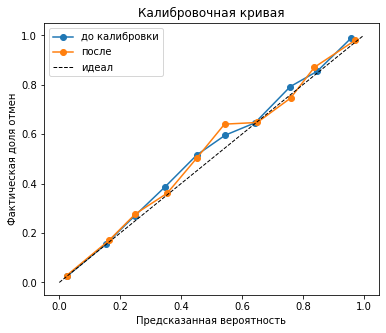

In [64]:
fig, ax = plt.subplots(figsize=(6, 5))

for label, p in [('до калибровки', proba_raw), ('после', proba_cal)]:
    frac, mean_pred = calibration_curve(y_calib, p, n_bins=10)
    ax.plot(mean_pred, frac, 'o-', label=label)

ax.plot([0, 1], [0, 1], 'k--', lw=1, label='идеал')
ax.set_xlabel('Предсказанная вероятность')
ax.set_ylabel('Фактическая доля отмен')
ax.legend()
ax.set_title('Калибровочная кривая')
plt.show()

Применён изотонический метод: он непараметрический и подходит при большом объёме данных (18 439 наблюдений в тренировочной выборке). Калибратор обучен на тренировочных данных, калибровочная выборка сохранена для поиска порога.

Кривая LightGBM изначально близка к диагонали; заметное отклонение есть только в среднем диапазоне вероятностей 0.3–0.6, где модель немного занижает риск. ROC-AUC практически не изменился (0.8999 → 0.8991): калибровка меняет значения вероятностей, но не их порядок.

### Поиск порога классификации

In [65]:
thresholds = np.arange(0.05, 0.96, 0.01)
ir_values = [calc_ir(y_calib, (proba_cal >= t).astype(int)) for t in thresholds]

best_idx = int(np.argmax(ir_values))
best_threshold = thresholds[best_idx]

print('Оптимальный порог:', round(best_threshold, 2))
print('IR при нём:       ', f'{ir_values[best_idx]:,.0f} ₽')
print('IR при 0.5:       ', f'{calc_ir(y_calib, (proba_cal >= 0.5).astype(int)):,.0f} ₽')

Оптимальный порог: 0.4
IR при нём:        104,696,500 ₽
IR при 0.5:        93,846,500 ₽


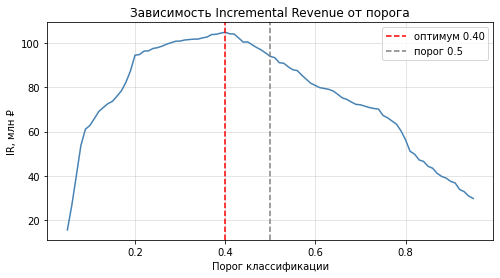

In [66]:
plt.figure(figsize=(8, 4))
plt.plot(thresholds, np.array(ir_values) / 1e6, color='steelblue')
plt.axvline(best_threshold, ls='--', c='red',
            label=f'оптимум {best_threshold:.2f}')
plt.axvline(0.5, ls='--', c='gray', label='порог 0.5')
plt.xlabel('Порог классификации')
plt.ylabel('IR, млн ₽')
plt.title('Зависимость Incremental Revenue от порога')
plt.legend()
plt.grid(alpha=0.4)
plt.show()

Оптимальный порог — 0.40: IR 104.7 млн ₽ против 93.8 млн при пороге 0.5, прирост 10.9 млн ₽.

Кривая пологая в диапазоне 0.20–0.45: небольшое отклонение порога не приводит к существенной потере дохода. Ниже 0.2 IR резко падает из-за ложных отмен, выше 0.5 — постепенно снижается из-за пропущенных.

Порог найден на калибровочной выборке.

### Анализ матрицы классификаций

In [67]:
proba_test = calibrated.predict_proba(X_test)[:, 1]

rows = []
for name, y_true, proba in [('калибровочная', y_calib, proba_cal),
                            ('тестовая', y_test, proba_test)]:
    pred = (proba >= best_threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    rows.append([name, tn, fp, fn, tp,
                 round(roc_auc_score(y_true, proba), 4),
                 round(calc_ir(y_true, pred) / 1e6, 1),
                 round(calc_ir_relative(y_true, pred), 1)])

stab = pd.DataFrame(rows, columns=['выборка', 'TN', 'FP', 'FN', 'TP',
                                   'ROC-AUC', 'IR, млн', 'IR, %'])
display(stab)

,выборка,TN,FP,FN,TP,ROC-AUC,"IR, млн","IR, %"
0,калибровочная,3771,545,519,1312,0.8991,104.7,65.3
1,тестовая,4352,221,280,1294,0.9775,125.9,65.1


In [68]:
ir_test = [calc_ir(y_test, (proba_test >= t).astype(int)) for t in thresholds]
print('Оптимум на тесте:', round(thresholds[int(np.argmax(ir_test))], 2))
print(f'IR на тесте при пороге {best_threshold:.2f}:',
      f'{calc_ir(y_test, (proba_test >= best_threshold).astype(int)):,.0f} ₽')
print('IR на тесте при его оптимуме:', f'{max(ir_test):,.0f} ₽')

Оптимум на тесте: 0.27
IR на тесте при пороге 0.40: 125,891,500 ₽
IR на тесте при его оптимуме: 131,565,000 ₽


Бизнес-результат стабилен: относительный IR на калибровочной и тестовой выборках почти совпадает — 65.3% и 65.1%.

ROC-AUC на тесте заметно выше — 0.978 против 0.899. Тестовый период длиннее (2020–2025) и доля отмен в нём ниже (25.6% против 29.8%); вероятно, у клиентов в этот период больше истории и отзывов, а признаки из отзывов — одни из самых сильных. Это нужно перепроверить на реальном потоке данных.

Оптимальный порог на тестовой выборке составил бы 0.27 против 0.40, найденного на калибровочной. Потеря от применения «чужого» порога — 5.7 млн ₽, или 4.3% от максимума.

### Фиксирование итоговой модели

In [69]:
FINAL_MODEL = calibrated
FINAL_THRESHOLD = best_threshold
pred_test = (proba_test >= best_threshold).astype(int)

print('Модель:', 'LGBMClassifier + изотоническая калибровка')
print('Гиперпараметры:')
for k, v in study_lgbm.best_params.items():
    print(f'  {k}: {v}')
print(f'\nПорог классификации: {FINAL_THRESHOLD:.2f}')
print(f'ROC-AUC на тесте: {roc_auc_score(y_test, proba_test):.4f}')
print(f'Относительный IR на тесте: {calc_ir_relative(y_test, pred_test):.1f}%')

Модель: LGBMClassifier + изотоническая калибровка
Гиперпараметры:
  n_estimators: 311
  learning_rate: 0.025584514802677177
  num_leaves: 17
  max_depth: 8
  min_child_samples: 55
  subsample: 0.6383044986855074
  colsample_bytree: 0.7699245468433484

Порог классификации: 0.40
ROC-AUC на тесте: 0.9775
Относительный IR на тесте: 65.1%


### Анализ важности признаков

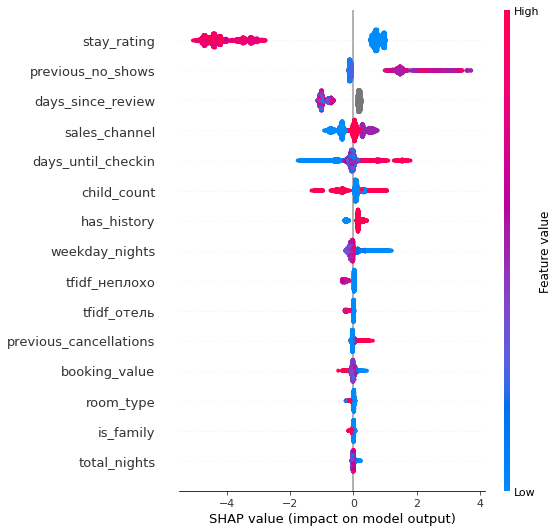

In [70]:
shap_model = LGBMClassifier(**study_lgbm.best_params,
                            random_state=RANDOM_STATE, verbose=-1)
shap_model.fit(X_train, y_train)

explainer = shap.TreeExplainer(shap_model)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test,
                  feature_names=all_feature_names,
                  max_display=15, show=False)
plt.tight_layout()
plt.show()

In [71]:
# Числовой рейтинг для выводов
importance = pd.DataFrame({
    'признак': all_feature_names,
    'важность': np.abs(shap_values).mean(axis=0),
}).sort_values('важность', ascending=False).reset_index(drop=True)

display(importance.head(15))

,признак,важность
0,stay_rating,2.714307
1,previous_no_shows,0.932361
2,days_since_review,0.613762
3,sales_channel,0.319506
4,days_until_checkin,0.317165
5,child_count,0.227347
6,has_history,0.193199
7,weekday_nights,0.123422
8,tfidf_неплохо,0.104728
9,tfidf_отель,0.059154


In [72]:
print(df.groupby('previous_no_shows')['target'].agg(['mean', 'size']).round(3))

                    mean   size
previous_no_shows              
0                  0.293  13408
1                  0.298  11180
2                  0.269   4288
3                  0.238   1435
4                  0.207    386
5                  0.222     36


Для оценки важности использован SHAP: в отличие от встроенной feature_importances_, он показывает не только силу, но и направление влияния каждого признака, что необходимо для бизнес-интерпретации.

Два первых места занимают признаки, связанные с наличием предыдущего отзыва (days_since_review — 1.70, stay_rating — 0.99). Их суммарный вклад превышает вклад всех остальных признаков. На графике видно, что модель использует days_since_review преимущественно как индикатор наличия истории: пропуски смещают предсказание в сторону отмены.

Начиная с третьей позиции идут содержательные факторы: горизонт бронирования, канал продаж, состав гостей, длительность проживания. Из 40 текстовых признаков заметный вклад дают два оценочных слова — «отличный» и «неплохо», оба снижают вероятность отмены.

Отдельная проверка previous_no_shows выявила расхождение: прямая зависимость по данным показывает снижение доли отмен с 29.3% до 20.7% с ростом числа прошлых заездов, тогда как SHAP указывает противоположное направление. Это признак взаимодействия с другими переменными, а не самостоятельного эффекта, поэтому в бизнес-интерпретацию он не выносится.

## Этап 3: расчёт экономической эффективности модели

In [73]:
tn, fp, fn, tp = confusion_matrix(y_test, pred_test, labels=[0, 1]).ravel()

n = len(y_test)
print('Тестовая выборка:', n, 'броней')
print(f'TN={tn}  FP={fp}  FN={fn}  TP={tp}')

Тестовая выборка: 6147 броней
TN=4352  FP=221  FN=280  TP=1294


In [74]:
# Доля отмен
cancel_before = (y_test == 1).sum() / n
cancel_after = fn / n

dyn_cancel = (cancel_before - cancel_after) / cancel_before * 100

print(f'Доля отмен до:    {cancel_before:.3f}')
print(f'Доля отмен после: {cancel_after:.3f}')
print(f'Динамика:         {dyn_cancel:.1f}%')

Доля отмен до:    0.256
Доля отмен после: 0.046
Динамика:         82.2%


In [75]:
# Загрузка отеля
occ_before = (y_test == 0).sum() / n
occ_after = tn / n

dyn_occ = (occ_before - occ_after) / occ_before * 100

print(f'Загрузка до:    {occ_before:.3f}')
print(f'Загрузка после: {occ_after:.3f}')
print(f'Динамика:       {dyn_occ:.1f}%')

Загрузка до:    0.744
Загрузка после: 0.708
Динамика:       4.8%


In [76]:
# IR
ir_before = (y_test == 0).sum() * AVG_REV - (y_test == 1).sum() * LOST_REV
ir_after = tp * PER_REBOOKING + tn * AVG_REV - fp * COST_FP - fn * LOST_REV

print(f'IR до:          {ir_before:>15,.0f} ₽')
print(f'IR после:       {ir_after:>15,.0f} ₽')
print(f'IR (разница):   {ir_after - ir_before:>15,.0f} ₽')
print(f'Относительный:  {(ir_after - ir_before) / abs(ir_before) * 100:>14.1f}%')

IR до:              193,435,500 ₽
IR после:           319,327,000 ₽
IR (разница):       125,891,500 ₽
Относительный:            65.1%


Расчёт выполнен на тестовой выборке (6147 бронирований). Показатели «до внедрения» получены из фактических значений y_test, «после» — из предсказаний модели при пороге 0.40.

Доля отмен снизилась с 25.6% до 4.6%. Загрузка снизилась с 74.4% до 70.8%, то есть на 4.8% — в пределах допустимых 8%. Расчёт консервативный: в загрузку засчитываются только брони, состоявшиеся без вмешательства модели (TN).

## Этап 4: выводы по проекту

### Выводы о проделанной работе

- Подготовка данных. Данные выгружены из PostgreSQL через SQLAlchemy: hotel_bookings (35 341 бронирование) и hotel_reviews (25 177 отзывов).
- EDA выявил и исправил:
    - 4608 полных дубликатов (7.7%), включая дублирование booking_id — удалены, осталось 30 733 брони
    - adult_count со значениями 100, 200, 300 у 2151 записи. Распределение внутри группы (41% / 40% / 18%) повторяет распределение обычных значений 1, 2, 3 — установлена порча данных множителем 100, значения восстановлены делением
    - Опечатка не выбрант в meal_plan (507 записей) — объединена с не выбран
    - 1229 записей с нулевой стоимостью. Проверка показала отсутствие отдельного сегмента: распределение по каналам (34.5/33.4/32.1) и доля отмен (29.1% против 28.8%) совпадают с общими. Ноль признан невозможным значением и заменён на пропуск
    - Редкие категории тип_питания_3 (5), тип_3 (8), тип_7 (143), тип_5 (242) объединены, чтобы избежать переобучения при разбиении выборок
    - booking_value слабо информативен: 74% броней идут по единому тарифу 6700 ₽ за ночь, цена не зависит ни от типа номера, ни от числа гостей, доля отмен в базовом и небазовом тарифе одинакова

- Анализ временной структуры показал неравномерность: объём броней достигает пика в 2019–2020 годах и падает почти до нуля к 2024. Утверждение заказчика о росте отмен за два года не подтвердилось — доля отмен стабильна до 2021 года и далее снижается. Признак «год бронирования» исключён из модели, так как обучение на историческом периоде с применением к будущему завысило бы метрики без реальной предсказательной способности.

- Объединение таблиц. Выполнено через merge_asof по ближайшей предшествующей дате отзыва внутри одного клиента (by='customer_id', direction='backward', allow_exact_matches=False). Идентификатор клиента восстановлен из таблицы отзывов по booking_id. Корректность подтверждена: ни одного случая, когда отзыв датирован позже или в день бронирования. Прошлый отзыв найден у 8328 броней (27.1%).

- При проверке обнаружена особенность данных: отзыв существует только по состоявшимся бронированиям, поэтому его наличие односторонне определяет класс. Вопрос вынесен на ревью, подтверждено, что для данной задачи это допустимо.

- Новые признаки. Создано 11 признаков: дата заезда и производные от неё (season, checkin_month, checkin_weekday), длительность проживания (total_nights, weekend_ratio), состав гостей (total_guests, is_family), история клиента (reliability, has_history, days_since_review).

- Из текстов отзывов получено 40 признаков через TfidfVectorizer. Использованы униграммы: тексты имеют шаблонную структуру, и при биграммах более половины словаря занимали фрагменты трёх повторяющихся фраз с полной корреляцией между колонками. Применены русские стоп-слова, min_df=20 и max_df=0.6. Векторизатор обучен только на тренировочной выборке.

- Три признака (review_length, review_words, has_review_flag) исключены как дублирующие stay_rating с корреляцией выше 0.99.

- Итоговая матрица — 65 признаков: 25 табличных и 40 текстовых.

- Разбиение выборок. Выполнено хронологически: данные отсортированы по booking_date, выборки выделены последовательными блоками 60/20/20. Стратификация не применяется — при разбиении по времени баланс классов задан данными. Выборки покрывают разные по длительности периоды из-за падения объёма бронирований после 2021 года.

- Оптимизация Optuna: 30 испытаний на модель, кросс-валидация на трёх фолдах, валидационная подвыборка 2000 наблюдений, целевая метрика — Incremental Revenue. Для LightGBM подбирались семь гиперпараметров, для CatBoost — пять.

- После оптимизации на калибровочной выборке: LightGBM — ROC-AUC 0.8999, IR 59.2%; CatBoost — 0.8951 и 59.0%. Итоговая модель — LightGBM с параметрами n_estimators=311, learning_rate=0.026, num_leaves=17, max_depth=8, min_child_samples=55, subsample=0.638, colsample_bytree=0.770.

- Калибровка и порог. Применена изотоническая калибровка (CalibratedClassifierCV, cv=3) на тренировочной выборке. ROC-AUC практически не изменился (0.8999 → 0.8991), что ожидаемо: калибровка меняет значения вероятностей, но не их порядок.

- Оптимальный порог найден перебором на калибровочной выборке — 0.40 при IR 104.7 млн ₽ против 93.8 млн ₽ при пороге 0.5. Смещение ниже 0.5 обусловлено асимметрией цены ошибок: пропущенная отмена стоит 64 500 ₽, ложное срабатывание — 7000 ₽.

- Стабильность. Расхождение относительного IR — 1.2 п.п. Оптимальный порог на тестовой выборке составил бы 0.27 против 0.40, найденного на калибровочной. Потеря от применения «чужого» порога — 5.7 млн ₽ из 131.6 млн, или 4.3%.

- Анализ важности. Использован SHAP: в отличие от встроенной feature_importances_, он показывает не только силу, но и направление влияния, что необходимо для бизнес-интерпретации.

### Выводы по анализу эффективности модели

**Достижение цели проекта**

Цель — построить модель, прогнозирующую вероятность отмены брони и позволяющую снизить финансовые потери сети. **Цель достигнута:** все три целевых показателя выполнены на тестовой выборке из 6147 бронирований.

Модель классифицирует бронирования с ROC-AUC 0.978. При пороге 0.40 из 1574 фактических отмен заранее выявляется 1294 (82.2%), что даёт менеджерам время на перепродажу номера.

**Результаты по ключевым метрикам**

**1. Доля отмен бронирования

- До внедрения: 25.6% (1574 отмены из 6147)
- После внедрения: 4.6% (280 невыявленных отмен)
- Изменение: (25.6 − 4.6) / 25.6 × 100% = −82.2%

Целевой показатель — не более 10%. Достигнут с запасом. Заказчик ставил задачу снизить долю поздних отмен до 10% за шесть месяцев; расчёт показывает выход на 4.6%.

**2. Загрузка отелей**

- До внедрения: 74.4% (4573 состоявшиеся брони)
- После внедрения: 70.8% (4352 брони, состоявшиеся естественным образом)
- Изменение: (74.4 − 70.8) / 74.4 × 100% = −4.8%

Расчёт консервативный: в загрузку засчитываются только брони, состоявшиеся без вмешательства модели (TN). Верно предсказанные отмены (TP) исключены, поскольку доход от их перепродажи уже отражён в IR через параметр PerRebooking, и повторный учёт задваивал бы один и тот же эффект.

Целевой показатель — снижение не более чем на 8%. Достигнут: 4.8%.

**3. Прирост дохода (Incremental Revenue)**

- Доход до внедрения: (4573 × 64 500) − (1574 × 64 500) = 193 435 500 ₽
- Доход после внедрения: (1294 × 45 000) + (4352 × 64 500) − (221 × 7000) − (280 × 64 500) = 319 327 000 ₽
- IR = 319 327 000 − 193 435 500 = 125 891 500 ₽
- Относительный IR = 125 891 500 / 193 435 500 × 100% = +65.1%

Целевой показатель — не менее 50%. Достигнут: 65.1%. В пересчёте на одно бронирование модель приносит около 20 500 ₽ дополнительного дохода.

**Итог:**

| Показатель | До | После | Изменение | Цель | Статус |
|---|---|---|---|---|---|
| Доля отмен | 25.6% | 4.6% | −82.2% | ≤ 10% | выполнено |
| Загрузка | 74.4% | 70.8% | −4.8% | падение ≤ 8% | выполнено |
| Относительный IR | — | — | +65.1% | ≥ 50% | выполнено |


**Ключевые факторы риска отмены**

Десять признаков с наибольшим вкладом по оценке SHAP:

1. stay_rating (вклад 2.71) и 3. days_since_review (0.61) — признаки, связанные с наличием предыдущего отзыва. Их значимость отражает структуру данных: отзыв в системе появляется только после состоявшегося проживания, поэтому его наличие косвенно указывает на клиента, который ранее доезжал до отеля. Содержательная интерпретация ограничена — рекомендуется контролировать вклад этих признаков после внедрения.

2. previous_no_shows (0.93) — число прошлых заездов клиента. Прямая зависимость по данным показывает снижение доли отмен с 29.3% при отсутствии истории до 20.7% при четырёх заездах. Однако направление вклада по SHAP противоположно, что указывает на взаимодействие с другими признаками, а не на самостоятельный эффект. Самостоятельная интерпретация некорректна, признак в рекомендации не выносится.

4. sales_channel (0.32) — канал бронирования. Корпоративные брони отменяются в 17% случаев, офлайн — в 29%, онлайн — в 41%. Онлайн-канал повышает риск в 2.4 раза относительно корпоративного: низкий барьер оформления означает и низкий барьер отказа.

5. days_until_checkin (0.32) — горизонт планирования. Бронирования с заездом через 1–8 дней отменяются в 9% случаев, через 209–300 дней — в 56%. Риск растёт в шесть раз с увеличением срока до заезда.

6. child_count (0.23) и 13. is_family (0.03) — состав гостей. Брони с одним ребёнком наиболее надёжны (15% отмен) против 31% у бездетных, но брони с двумя детьми — наиболее рискованные (45%).

7. has_history (0.19) — наличие истории взаимодействия с сетью.

8. weekday_nights (0.12) и 14. total_nights (0.02) — длительность проживания. Брони на одну буднюю ночь отменяются в 55% случаев против базовых 29%.

9. tfidf_неплохо (0.10) и 10. tfidf_отель (0.06) — признаки из текстов отзывов. Из 40 текстовых признаков заметный вклад дают два; оценочная лексика предыдущего отзыва служит маркером лояльности клиента.

**Что не влияет.** Сезонность в данных отсутствует: доля отмен по всем двенадцати месяцам заезда лежит в диапазоне 27.4–30.4% при базовом уровне 28.8%. Не подтвердилось влияние типа питания, бронирования парковки и статуса постоянного клиента. Стоимость бронирования также не дифференцирует классы.

**Рекомендации для бизнеса**

**1. Дифференцировать условия по горизонту бронирования.** Брони с заездом более чем через 150 дней составляют группу максимального риска (свыше 50% отмен). Для них целесообразно ввести невозвратный тариф со скидкой либо частичную предоплату. Клиенты, готовые внести предоплату, самоотбираются в надёжную группу, а остальные компенсируют риск скидкой на возвратный тариф.

**2. Усилить работу с онлайн-каналом.** Онлайн-бронирования дают 41% отмен против 17% у корпоративных, при этом составляют треть всех броней. Рекомендуется внедрить подтверждение брони за 7–10 дней до заезда с предложением гибкого переноса дат. Освободившиеся номера поступают в продажу заблаговременно, а не за сутки.

**3. Развивать корпоративный канал.** Наиболее устойчивый сегмент с долей отмен в 2.4 раза ниже среднего. Наращивание доли корпоративных броней снижает волатильность загрузки структурно, без участия модели.

**4. Внедрять модель поэтапно.** Начать с сегмента максимального риска — брони с горизонтом свыше 150 дней через онлайн-канал. Это позволит оценить фактическую точность на реальных данных до полного развёртывания.

**Ограничения расчёта**

Существенный вклад в предсказание вносят признаки, связанные с наличием предыдущего отзыва, что является особенностью текущей выгрузки данных. При внедрении рекомендуется провести повторную оценку на данных, где сбор отзывов организован иначе, — фактический экономический эффект может оказаться ниже расчётного.